# Лабораторная работа №3. Регрессионный анализ
Курбатов М. П., группа 4417. Вариант 13, лист var3.

Цель: изучить простую и полиномиальную регрессию, сравнить методы прогноза зарплаты. Выполнены основные задания и дополнительные №11, 12, 15 по методичке. Пути к исходным файлам задаются в первой кодовой ячейке.

## Загрузка файлов и библиотек


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

excel_file = '/content/regression (1).xlsx'  # Укажите путь к Excel.
salary_file = '/content/salary.csv'  # Укажите путь к CSV.

df = pd.read_excel(excel_file, sheet_name='var3')
salary = pd.read_csv(salary_file)
salary_raw = salary.copy()  # Исходные данные сохраняются отдельно.

# Одна функция для одинакового расчёта метрик всех моделей.
def metrics(y, prediction):
    mse = mean_squared_error(y, prediction)
    return {'MAE': mean_absolute_error(y, prediction),
            'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y, prediction)}


## Часть 1. Простая линейная регрессия
### 1. Описание данных и корреляции
`x1` и `x2` — числовые признаки, `y` — целевая переменная. Предметный смысл и единицы измерения в задании не указаны.


In [2]:
display(df.head(20))
display(df.describe())
print('Пропуски:', df.isna().sum().to_dict())
print('Дубликаты:', df.duplicated().sum())
display(df.corr(method='pearson'))


Пропуски: {'x1': 0, 'x2': 0, 'y': 0}
Дубликаты: 0


,x1,x2,y
0,1.696315,-0.548550,0.870770
1,-0.560186,1.176442,0.539647
2,1.493260,0.386962,1.049902
3,0.162986,-1.232673,-1.490034
4,0.344845,0.740232,1.737131
5,1.756825,1.342264,3.748636
6,-1.234110,0.665019,0.988839
7,0.853258,-1.163597,-0.842644
8,0.318094,-0.487262,-0.704140
9,1.779796,-1.369448,0.244140


,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,0.000007,-0.000038,0.483917
std,1.155357,1.155261,1.670779
min,-1.998745,-1.996808,-3.498375
25%,-0.998825,-0.999651,-0.774310
50%,0.000264,0.001129,0.434032
75%,0.997258,0.998857,1.741084
max,1.997294,1.997547,5.060642


,x1,x2,y
x1,1.000000,0.010576,0.000333
x2,0.010576,1.000000,0.849765
y,0.000333,0.849765,1.000000


В наборе 1000 строк, пропусков и дубликатов нет. Корреляция `x1` и `y` близка к нулю (0,0003). Для `x2` и `y` она равна примерно 0,85: линейная связь сильная и положительная. Слабая корреляция сама по себе не исключает нелинейную связь.


### 2–9. Обучение двух моделей, прогнозы и графики
Для обеих моделей использую одно разбиение: 75% строк для обучения, 25% для валидации. Модели сравниваются на одинаковых наблюдениях.

MAE — средняя абсолютная ошибка, MSE — средняя квадратичная ошибка, RMSE — её корень в единицах целевой переменной. Чем меньше эти ошибки, тем лучше. R² показывает качество относительно прогноза среднего на оцениваемой выборке: максимум равен 1, значение может быть отрицательным.


x1: y = -0.03199 * x1 +0.45030
x2: y = 1.21685 * x2 +0.45990


,Факт,Прогноз,Прогноз − факт
2,1.049902,0.402531,-0.647371
3,-1.490034,0.445088,1.935122
10,2.025431,0.455829,-1.569602
23,-1.819759,0.433458,2.253217
25,4.607668,0.513399,-4.094269
29,0.501901,0.434531,-0.067369
30,3.285727,0.494037,-2.791690
31,-0.787755,0.413982,1.201737
33,2.874938,0.489942,-2.384997
39,0.572998,0.403627,-0.169370


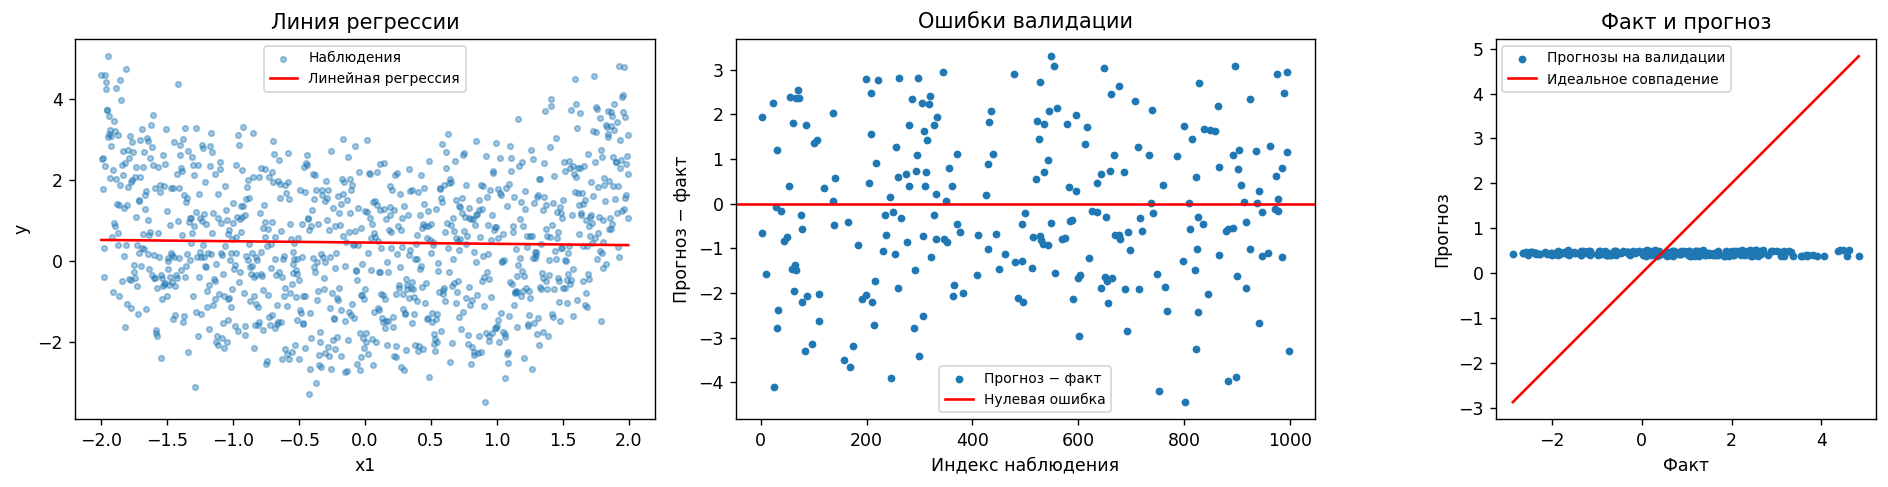

,Факт,Прогноз,Прогноз − факт
2,1.049902,0.930771,-0.119131
3,-1.490034,-1.040077,0.449957
10,2.025431,2.762180,0.736749
23,-1.819759,-0.992527,0.827232
25,4.607668,1.001304,-3.606364
29,0.501901,0.276615,-0.225286
30,3.285727,2.821461,-0.464265
31,-0.787755,-1.772563,-0.984808
33,2.874938,2.149737,-0.725202
39,0.572998,0.193730,-0.379268


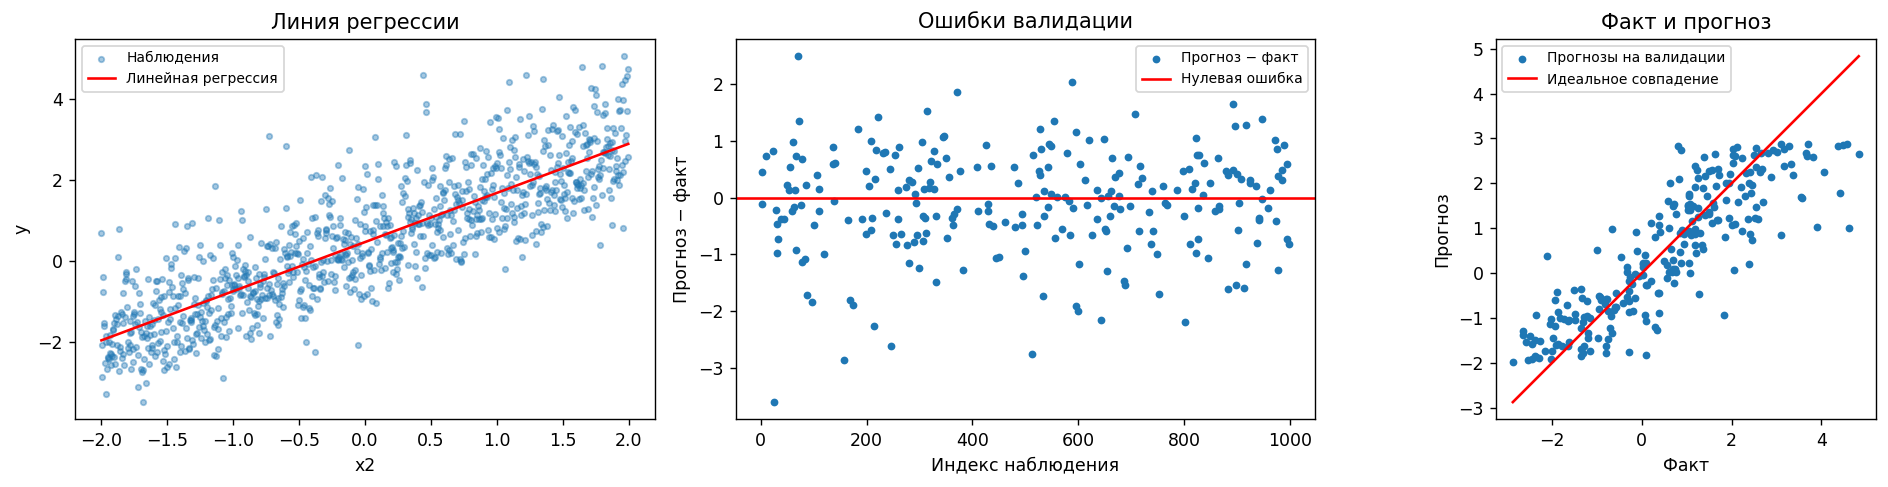

,Признак,MAE,MSE,RMSE,R2
0,x1,1.455234,3.075470,1.753702,-0.008890
1,x2,0.696717,0.823589,0.907518,0.729827


In [3]:
train_index, valid_index = train_test_split(df.index, test_size=0.25, random_state=42)
y_train_reg = df.loc[train_index, 'y']
y_valid_reg = df.loc[valid_index, 'y']
linear_results = []

for feature in ['x1', 'x2']:
    model = LinearRegression()
    model.fit(df.loc[train_index, [feature]], y_train_reg)
    prediction = model.predict(df.loc[valid_index, [feature]])
    linear_results.append({'Признак': feature, **metrics(y_valid_reg, prediction)})
    print(f'{feature}: y = {model.coef_[0]:.5f} * {feature} {model.intercept_:+.5f}')
    comparison = pd.DataFrame({'Факт': y_valid_reg, 'Прогноз': prediction})
    comparison['Прогноз − факт'] = comparison['Прогноз'] - comparison['Факт']
    with pd.option_context('display.max_rows', None):
        display(comparison.sort_index())

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    x_line = pd.DataFrame({feature: np.linspace(df[feature].min(), df[feature].max(), 200)})
    axes[0].scatter(df[feature], df['y'], s=10, alpha=0.4, label='Наблюдения')
    axes[0].plot(x_line[feature], model.predict(x_line), color='red', label='Линейная регрессия')
    axes[0].set(xlabel=feature, ylabel='y', title='Линия регрессии')
    errors = comparison.sort_index()['Прогноз − факт']
    axes[1].scatter(errors.index, errors, s=12, label='Прогноз − факт')
    axes[1].axhline(0, color='red', label='Нулевая ошибка')
    axes[1].set(xlabel='Индекс наблюдения', ylabel='Прогноз − факт', title='Ошибки валидации')
    lo = min(y_valid_reg.min(), prediction.min())
    hi = max(y_valid_reg.max(), prediction.max())
    axes[2].scatter(y_valid_reg, prediction, s=12, label='Прогнозы на валидации')
    axes[2].plot([lo, hi], [lo, hi], color='red', label='Идеальное совпадение')
    axes[2].set(xlabel='Факт', ylabel='Прогноз', title='Факт и прогноз')
    axes[2].set_aspect('equal', adjustable='box')
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(linear_results))


### 10. Вывод
Модель по `x2` точнее: MAE около 0,697 и R² около 0,730. Для `x1` MAE около 1,455, R² отрицательный. Поэтому из двух парных моделей выбираю модель по `x2`. На графике её прогнозы ближе к диагонали идеального совпадения.


## Часть 2. Полиномиальная регрессия
### 1–6. Сравнение степеней 2 и 3
Выбираю `x2`: в первой части он оказался полезнее для прогноза `y`. Проверю, улучшит ли добавление степеней этого признака качество по сравнению с прямой. Использую те же обучающие и валидационные строки. Степень сравниваю по MAE и R² на валидации.


Степень: 2
Степень: 3
Лучшая степень по MAE valid: 2


,Факт,Прогноз
521,-0.068690,-0.072733
737,0.373671,-0.447062
740,-1.625924,-1.506173
660,-0.280631,-0.620072
411,1.089776,0.847241
678,-2.158199,-1.701565
626,0.561486,-0.119271
513,1.837413,-0.918179
859,-1.183537,-1.418152
136,0.385483,1.268524


,Факт,Прогноз
521,-0.068690,-0.074326
737,0.373671,-0.449402
740,-1.625924,-1.505507
660,-0.280631,-0.622527
411,1.089776,0.848595
678,-2.158199,-1.699083
626,0.561486,-0.120987
513,1.837413,-0.920367
859,-1.183537,-1.418150
136,0.385483,1.270811


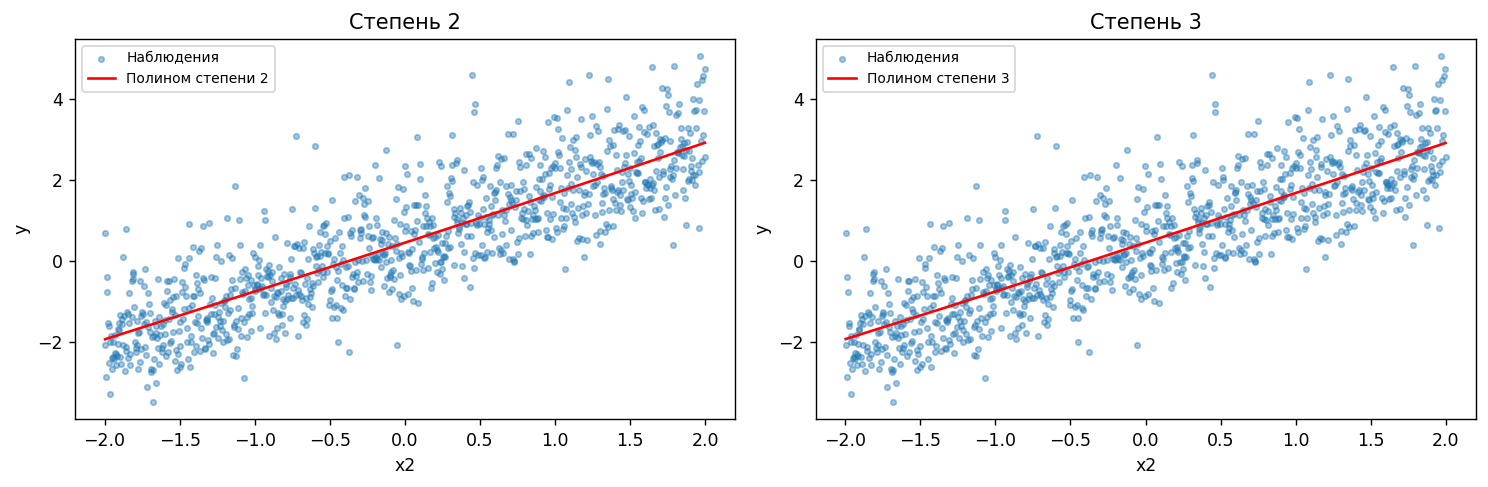

,Степень,R2 train,R2 valid,MAE train,MAE valid
0,2,0.718418,0.729167,0.685776,0.698166
1,3,0.718420,0.729191,0.685769,0.698246


In [4]:
poly_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, degree in zip(axes, [2, 3]):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(df.loc[train_index, ['x2']])
    X_valid_poly = poly.transform(df.loc[valid_index, ['x2']])
    model_poly = LinearRegression()
    model_poly.fit(X_train_poly, y_train_reg)
    train_prediction = model_poly.predict(X_train_poly)
    valid_prediction = model_poly.predict(X_valid_poly)
    poly_results.append({'Степень': degree,
                         'R2 train': r2_score(y_train_reg, train_prediction),
                         'R2 valid': r2_score(y_valid_reg, valid_prediction),
                         'MAE train': mean_absolute_error(y_train_reg, train_prediction),
                         'MAE valid': mean_absolute_error(y_valid_reg, valid_prediction)})
    print('Степень:', degree)
    display(pd.DataFrame({'Факт': y_valid_reg, 'Прогноз': valid_prediction}).head(20))
    x_line = pd.DataFrame({'x2': np.linspace(df['x2'].min(), df['x2'].max(), 200)})
    ax.scatter(df['x2'], df['y'], s=10, alpha=0.4, label='Наблюдения')
    ax.plot(x_line['x2'], model_poly.predict(poly.transform(x_line)), color='red',
            label=f'Полином степени {degree}')
    ax.set(xlabel='x2', ylabel='y', title=f'Степень {degree}')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
poly_table = pd.DataFrame(poly_results)
display(poly_table)
print('Лучшая степень по MAE valid:', int(poly_table.loc[poly_table['MAE valid'].idxmin(), 'Степень']))


### 7. Вывод
Степень выбираю по качеству на валидации, а не только на обучении. Слишком низкая степень может не описать изгиб зависимости, слишком высокая — подстроиться под шум. Для этого листа полиномы дают результат, близкий к линейной модели. Если улучшение мало, разумнее оставить более простую модель. Численные результаты двух степеней приведены в таблице выше.

Среди двух полиномов меньше MAE у степени 2: MAE valid = 0.6982, R² valid = 0.7292. Существенного преимущества перед прямой нет.


## Часть 3. Прогноз зарплаты
### 1–2. Обзор данных и целевая переменная
Целевая переменная — `salary`, годовая зарплата. `income` означает доход до текущей работы и используется как признак.

Числовые признаки: возраст (`age`), предыдущий доход (`income`), опыт (`experience`), результат теста (`score_test`), рабочие часы (`hours_worked`), расстояние до работы (`distance_to_work`), сбережения (`savings`), долги (`debt`). Категориальные: образование (`education`), город (`city`), сфера работы (`job_type`), семейное положение (`marital_status`), автомобиль (`car`), удалённая работа (`remote_work`).


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   object 
 9   city              1500 non-null   object 
 10  job_type          1500 non-null   object 
 11  marital_status    1500 non-null   object 
 12  car               1500 non-null   object 
 13  remote_work       1500 non-null   object 
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), object(6)
memory usage: 175.9+ KB
Пропуски: {'age': 0, 'income':

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842
5,25,11326.768555,3,73.022827,39,4.879219,11916.744037,6431.835876,Bachelor,Los Angeles,IT,Single,No,Yes,49665.609629
6,38,41579.497114,22,87.163120,49,11.706144,33558.588986,12271.330484,PhD,Chicago,Retail,Single,No,Yes,92451.866841
7,56,54713.055994,19,76.671392,38,9.224122,32785.043710,4876.906464,Bachelor,New York,Retail,Single,Yes,Yes,77558.755600
8,36,43636.766522,14,77.635691,72,1.134451,40287.795615,5796.929279,Master,Phoenix,Healthcare,Married,Yes,No,70917.649089
9,40,40306.859573,28,71.729474,58,7.096197,9083.212469,12941.384435,Master,New York,IT,Married,No,No,83196.215231


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


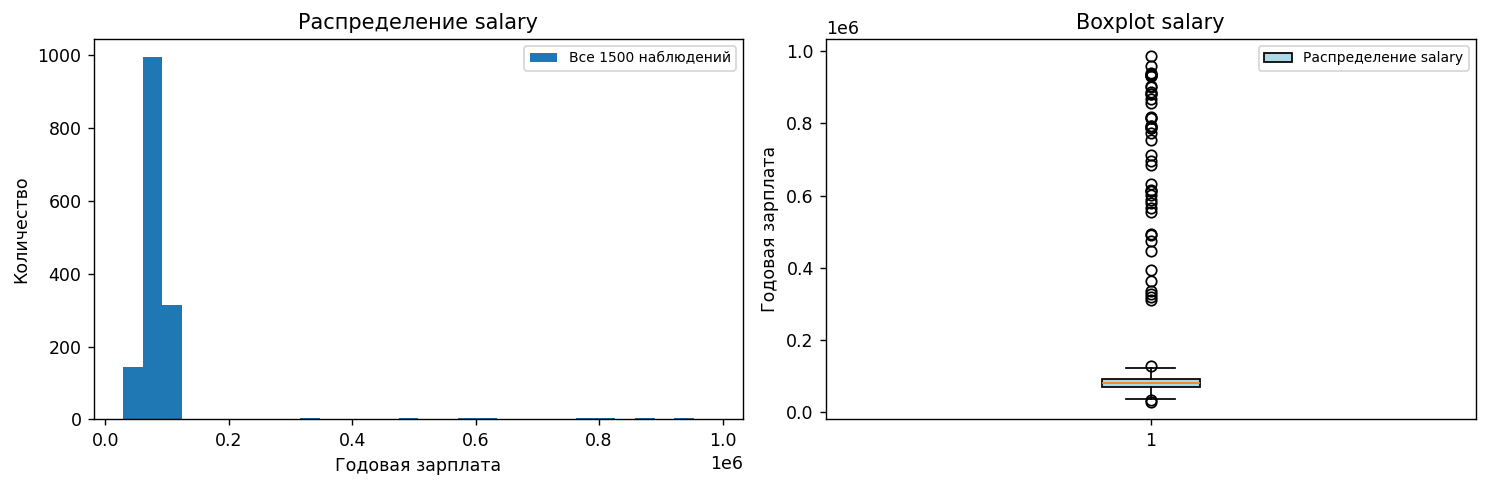

In [5]:
display(salary_raw.head(20))
salary_raw.info()
display(salary_raw.describe())
print('Пропуски:', salary_raw.isna().sum().to_dict())
print('Дубликаты:', salary_raw.duplicated().sum())
for column in salary_raw.select_dtypes(include='object'):
    print(column, ':', salary_raw[column].unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(salary_raw['salary'], bins=30, label='Все 1500 наблюдений')
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество', title='Распределение salary')
salary_box = axes[1].boxplot(
    salary_raw['salary'], patch_artist=True, boxprops={'facecolor': 'lightblue'}
)
axes[0].legend(fontsize=8)
axes[1].legend([salary_box['boxes'][0]], ['Распределение salary'], fontsize=8)
axes[1].set(ylabel='Годовая зарплата', title='Boxplot salary')
plt.tight_layout()
plt.show()


### 3–6. Подготовка данных
Согласно пункту 3 части 3 методички сначала обрабатываю выбросы и показываю распределение после обработки. Использую одно правило для всех строк исходного набора: зарплата должна находиться внутри [Q1 − 1,5·IQR; Q3 + 1,5·IQR]. Критерий IQR выбран для этой учебной работы; методичка не предписывает именно его.

Исходные 1500 строк сохранены в salary_raw. После применения правила остаются 1452 записи: удалены 46 высоких и 2 низких значения. Никакие точки не удаляются по величине ошибки модели. Затем очищенный набор разделяется на train и valid, как в пункте 5 методички. Метрики характеризуют только очищенный диапазон зарплат и напрямую не сопоставимы с оценкой на исходных 1500 строках.

Категории преобразую через get_dummies(drop_first=True), числовые признаки стандартизирую по train. Это правило очистки не доказывает, что каждая исключённая зарплата ошибочна в реальности.

Границы зарплаты: 36501.06 — 124718.65
Исходных строк: 1500
Удалено: 48 (снизу: 2 , сверху: 46 )
Осталось после очистки: 1452
Обучение: 1089 Валидация: 363


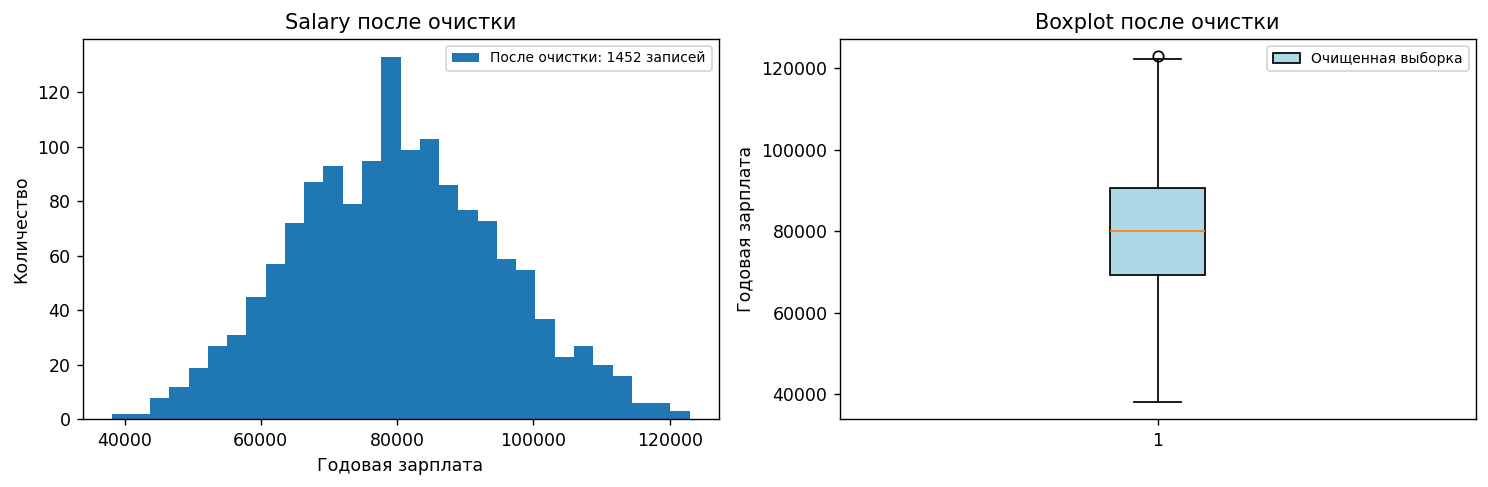

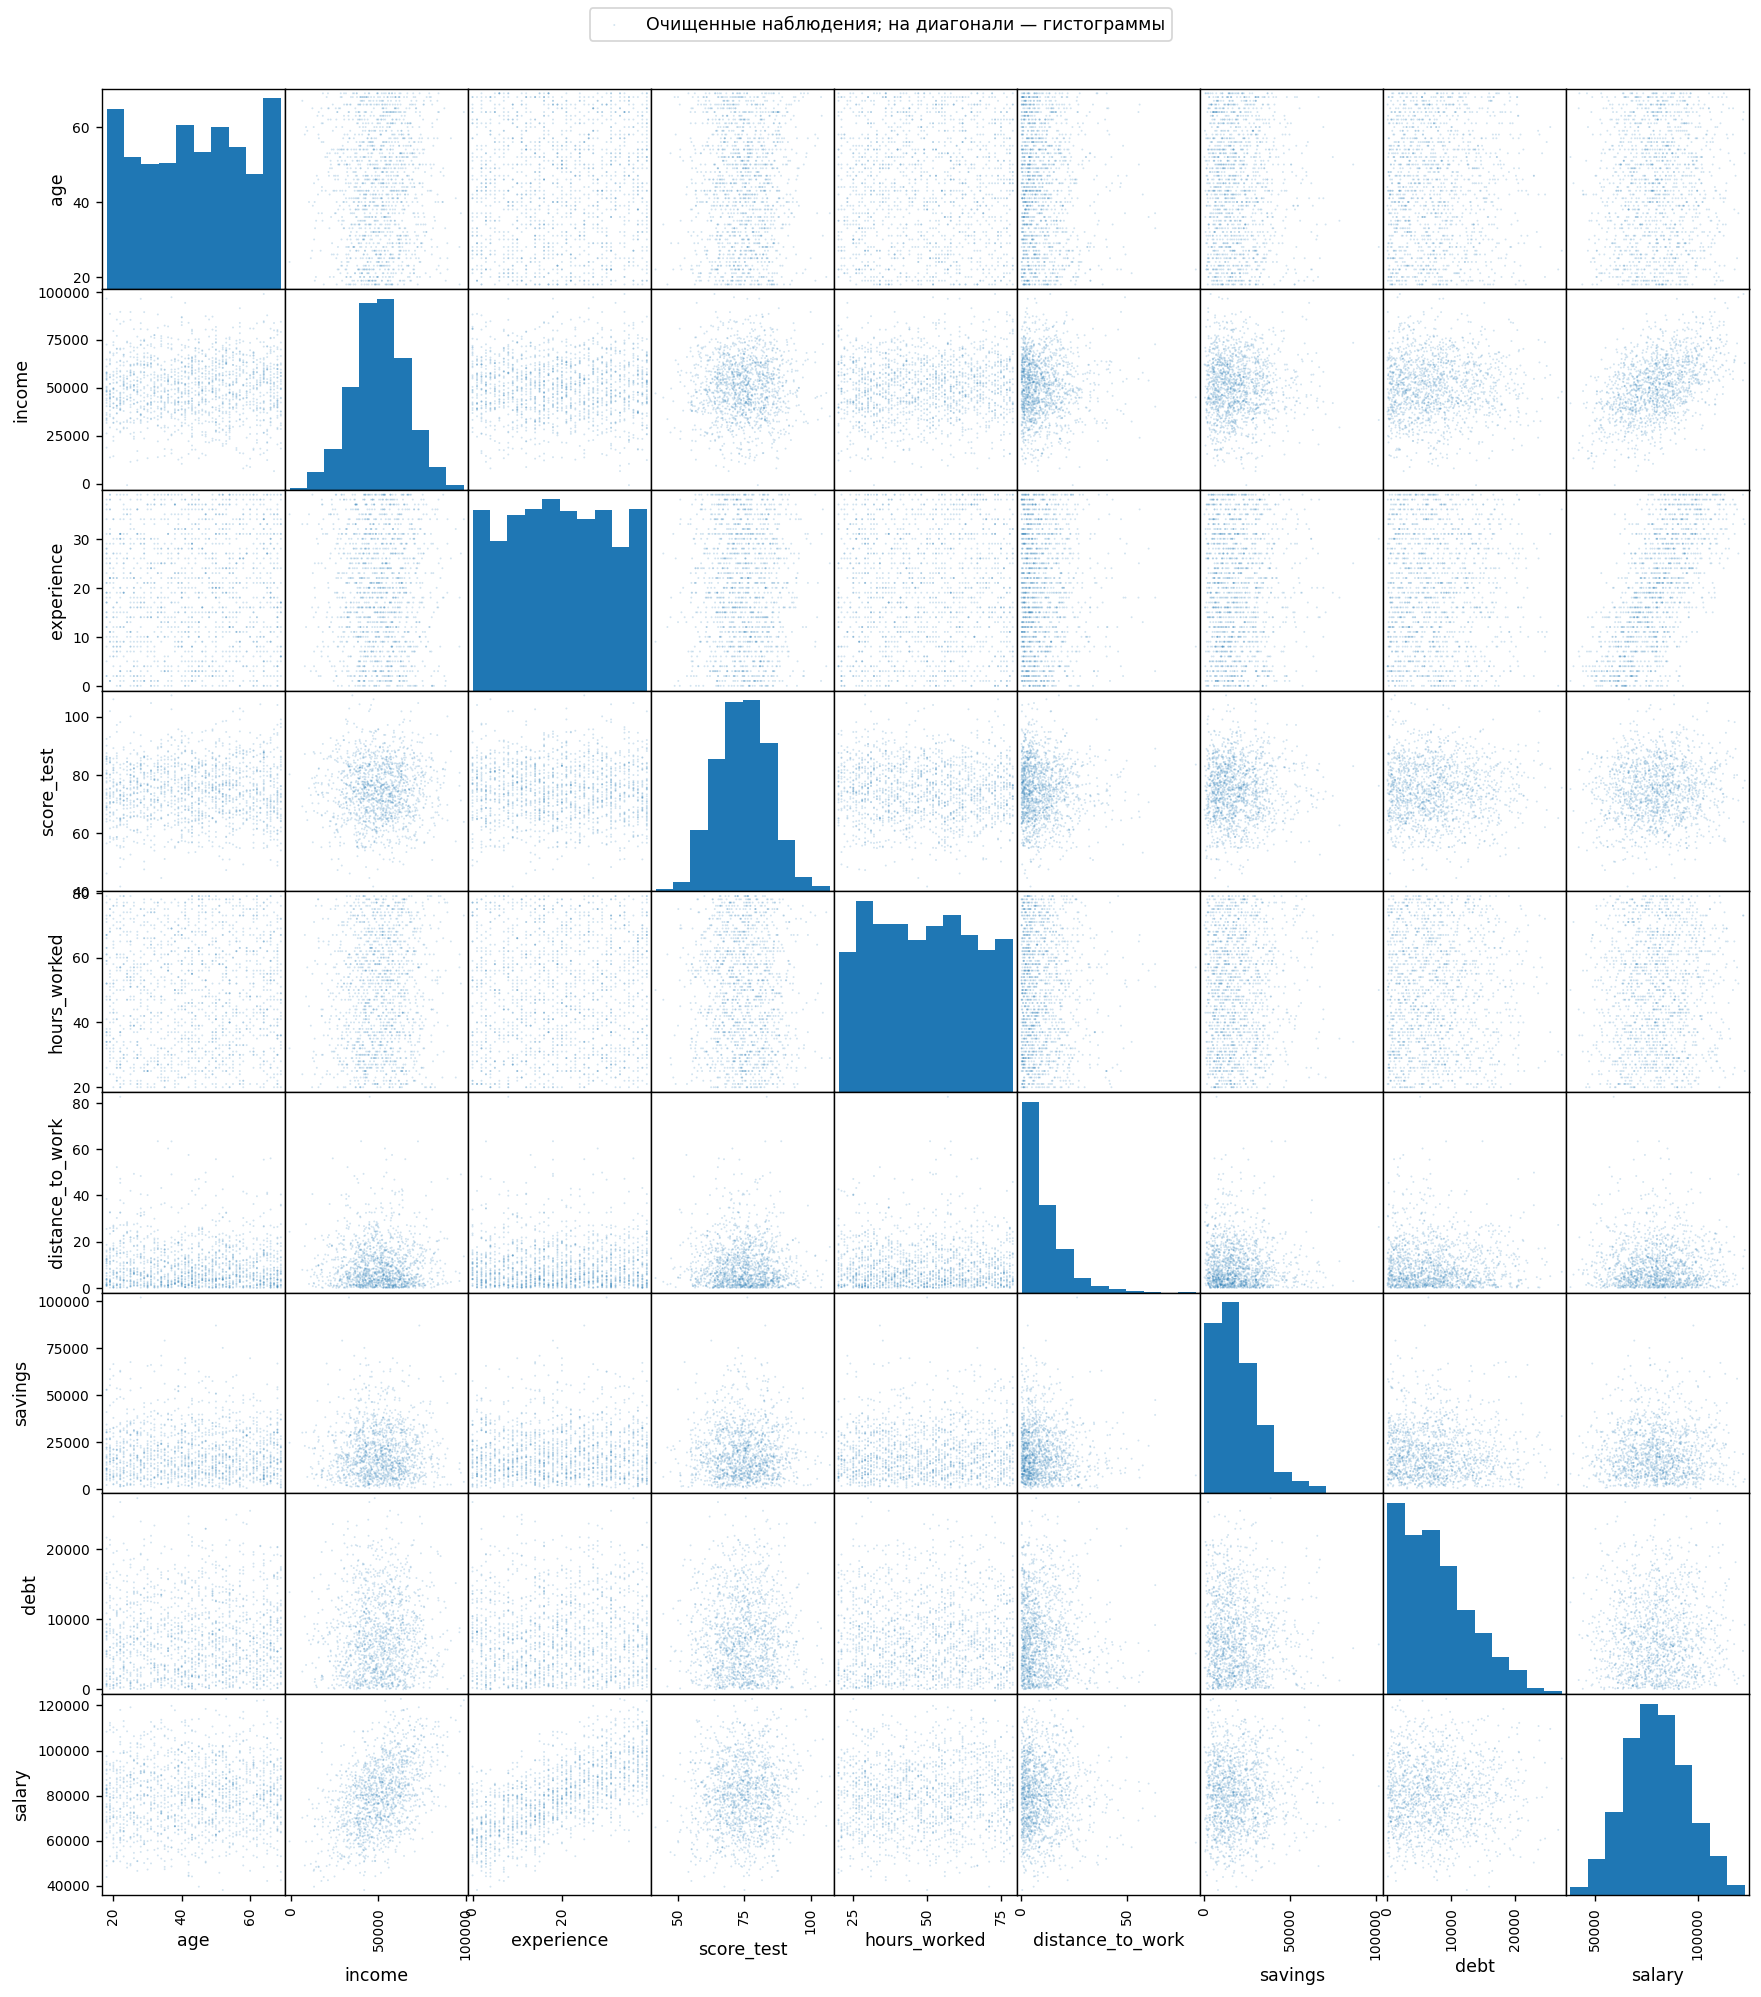

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education_High School,education_Master,education_PhD,city_Houston,city_Los Angeles,city_New York,city_Phoenix,job_type_Finance,job_type_Healthcare,job_type_IT,job_type_Retail,marital_status_Married,marital_status_Single,car_Yes,remote_work_Yes
1078,-1.642068,0.740118,-0.073564,-1.806830,0.268540,-0.666105,-0.887252,-0.370005,0,0,0,0,0,1,0,0,0,0,1,0,1,1,0
501,0.794547,0.683626,-0.769424,-0.688361,0.152768,0.121921,-0.807475,3.165379,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0
917,1.387237,0.986213,-0.073564,-1.266076,0.731629,1.058374,0.021540,0.297221,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0
55,-0.456688,1.282895,0.796262,0.386731,1.136832,0.998139,1.220951,1.146296,0,0,1,0,1,0,0,0,0,1,0,1,0,1,0
1002,-0.785960,-0.166238,1.666087,0.931398,-1.641700,1.505080,-0.151385,-0.074214,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1


In [6]:
# Границы рассчитываются один раз по исходному набору.
q1, q3 = salary_raw['salary'].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
keep = salary_raw['salary'].between(lower_bound, upper_bound)
salary = salary_raw.loc[keep].copy()
excluded_salary = salary_raw.loc[~keep].copy()
print(f'Границы зарплаты: {lower_bound:.2f} — {upper_bound:.2f}')
print('Исходных строк:', len(salary_raw))
print('Удалено:', len(excluded_salary),
      '(снизу:', (salary_raw['salary'] < lower_bound).sum(),
      ', сверху:', (salary_raw['salary'] > upper_bound).sum(), ')')
print('Осталось после очистки:', len(salary))
assert salary['salary'].between(lower_bound, upper_bound).all()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(salary['salary'], bins=30, label=f'После очистки: {len(salary)} записей')
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество', title='Salary после очистки')
axes[0].legend(fontsize=8)
clean_box = axes[1].boxplot(
    salary['salary'], patch_artist=True, boxprops={'facecolor': 'lightblue'}
)
axes[1].set(ylabel='Годовая зарплата', title='Boxplot после очистки')
axes[1].legend([clean_box['boxes'][0]], ['Очищенная выборка'], fontsize=8)
plt.tight_layout()
plt.show()

# Матрица рассеяния всех числовых признаков и цели на очищенных строках.
scatter_data = salary.select_dtypes(include='number')
scatter_axes = pd.plotting.scatter_matrix(
    scatter_data, figsize=(17, 17), diagonal='hist', alpha=0.2, s=5
)
scatter_figure = scatter_axes[0, 0].figure
scatter_figure.legend(
    handles=[scatter_axes[0, 1].collections[0]],
    labels=['Очищенные наблюдения; на диагонали — гистограммы'],
    loc='upper center', fontsize=10
)
scatter_figure.subplots_adjust(top=0.96)
plt.show()


# Разбиение выполняется после очистки. Для всех моделей одни и те же строки.
X = salary.drop(columns='salary')
y = salary['salary']
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print('Обучение:', len(y_train), 'Валидация:', len(y_valid))
assert len(y_train) + len(y_valid) == len(salary)
assert set(X_train.index).isdisjoint(X_valid.index)

numeric_columns = X_train.select_dtypes(include='number').columns
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_valid = pd.get_dummies(X_valid, drop_first=True, dtype=int)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_valid[numeric_columns] = scaler.transform(X_valid[numeric_columns])
display(X_train.head())


### 7–9, 12–13. Обучение и сравнение трёх методов
Использую линейную регрессию, kNN с пятью соседями и дерево с максимальной глубиной 5. Это заданные параметры для сравнения, подбор оптимальных параметров в обязательную часть не входит. Все три метода обучаю и проверяю на одинаковых строках.


In [7]:
models = {'Линейная регрессия': LinearRegression(),
          'kNN': KNeighborsRegressor(n_neighbors=5),
          'Дерево решений': DecisionTreeRegressor(max_depth=5, random_state=42)}
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_valid)
    predictions[name] = prediction
    results.append({'Модель': name, **metrics(y_valid, prediction)})

result_table = pd.DataFrame(results).set_index('Модель')
display(result_table)
comparison = pd.DataFrame({'Факт salary': y_valid})
for name, prediction in predictions.items():
    comparison[name] = prediction
with pd.option_context('display.max_rows', None):
    display(comparison.sort_index())


,MAE,MSE,RMSE,R2
Модель,,,,
Линейная регрессия,4915.832025,3.741947e+07,6117.145476,0.859079
kNN,8861.392840,1.173129e+08,10831.107575,0.558202
Дерево решений,7662.382661,8.766863e+07,9363.152800,0.669842


,Факт salary,Линейная регрессия,kNN,Дерево решений
15,63876.307670,68822.975867,74704.157517,63557.387485
23,111198.257761,119655.965645,104066.947821,114190.626398
29,44219.056055,60285.250428,72640.672574,54841.104106
30,90837.188701,74646.035563,70653.898881,63557.387485
31,94294.390163,85220.217604,87804.576912,76551.895877
32,91766.966835,87205.846082,83051.837788,85901.052892
44,71288.910020,67220.731703,83438.987070,71681.868118
45,68075.399817,59918.206922,65301.784023,63557.387485
49,83843.268389,80279.146998,82148.228281,76074.533896
50,90409.785269,85380.771857,81936.856590,86234.917110


### 10. Коэффициенты линейной регрессии
Коэффициент числового признака показывает изменение прогноза при росте признака на одно стандартное отклонение train, остальные признаки фиксированы. Коэффициент категории — отличие от базовой категории. Модули этих коэффициентов имеют разную интерпретацию, поэтому не являются безусловным общим рейтингом важности. Связь с прогнозом не доказывает причинное влияние.

Среди числовых признаков наибольшие по модулю коэффициенты: experience, income, score_test.

In [8]:
coefficients = pd.DataFrame({'Признак': X_train.columns,
                             'Коэффициент': models['Линейная регрессия'].coef_})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
display(coefficients.sort_values('Модуль', ascending=False))
print('Свободный член:', models['Линейная регрессия'].intercept_)
print('Базовые категории:')
for column in salary.select_dtypes(include='object'):
    print(column, ':', sorted(salary.loc[y_train.index, column].unique())[0])


Свободный член: 77305.29509498017
Базовые категории:
education : Bachelor
city : Chicago
job_type : Education
marital_status : Divorced
car : No
remote_work : No


,Признак,Коэффициент,Модуль
10,education_PhD,12614.640214,12614.640214
2,experience,10293.710290,10293.710290
1,income,7334.341444,7334.341444
9,education_Master,6587.020517,6587.020517
8,education_High School,-6250.536544,6250.536544
17,job_type_IT,3715.258270,3715.258270
15,job_type_Finance,2123.121149,2123.121149
13,city_New York,1393.721422,1393.721422
21,car_Yes,-1123.949400,1123.949400
3,score_test,1093.627752,1093.627752


### 11, 13. Визуализация факта и прогноза
Красная диагональ — идеальное совпадение. Чем ближе к ней точки, тем точнее прогноз.


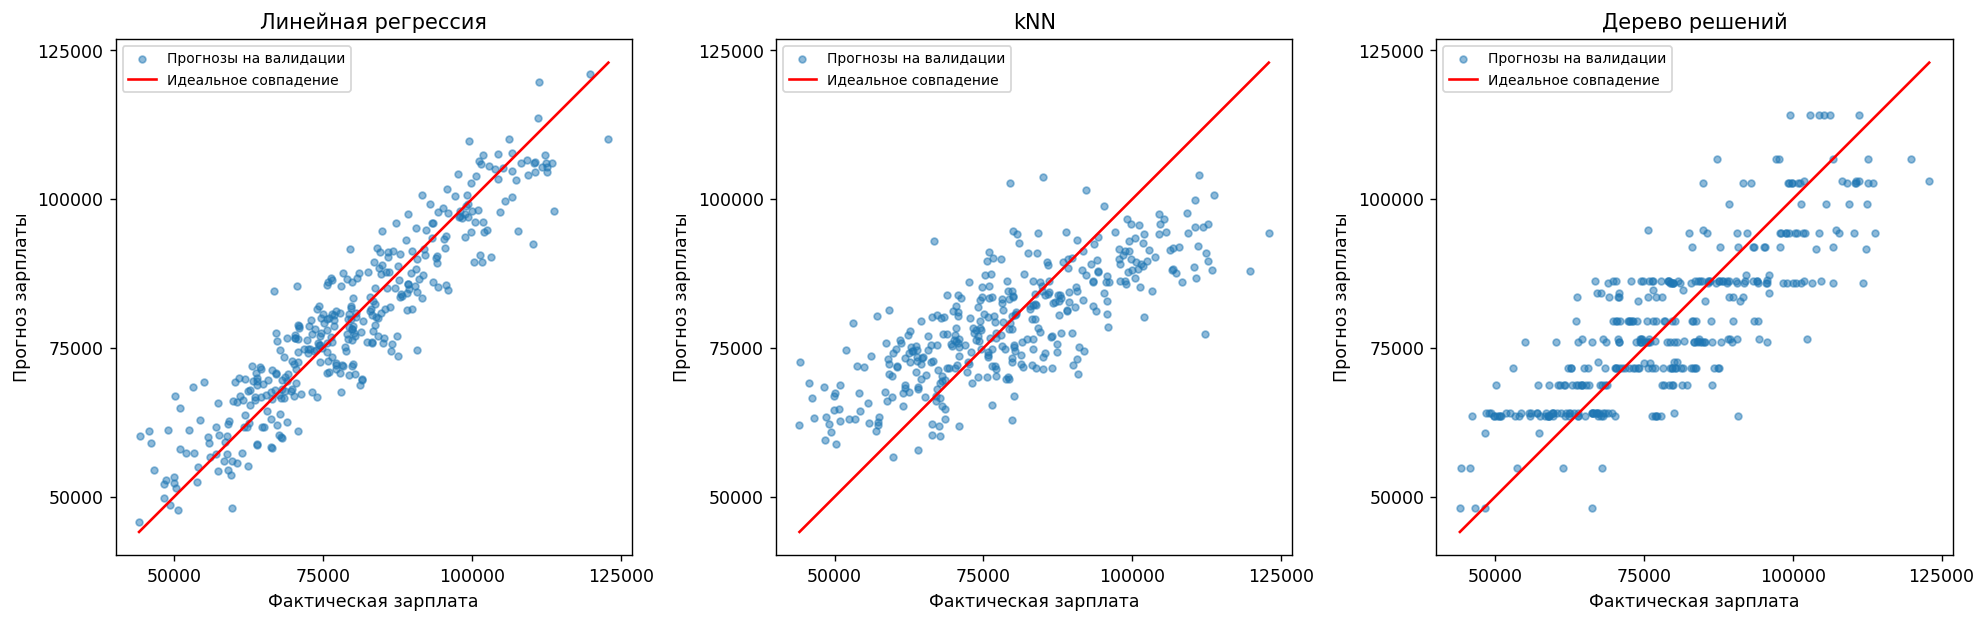

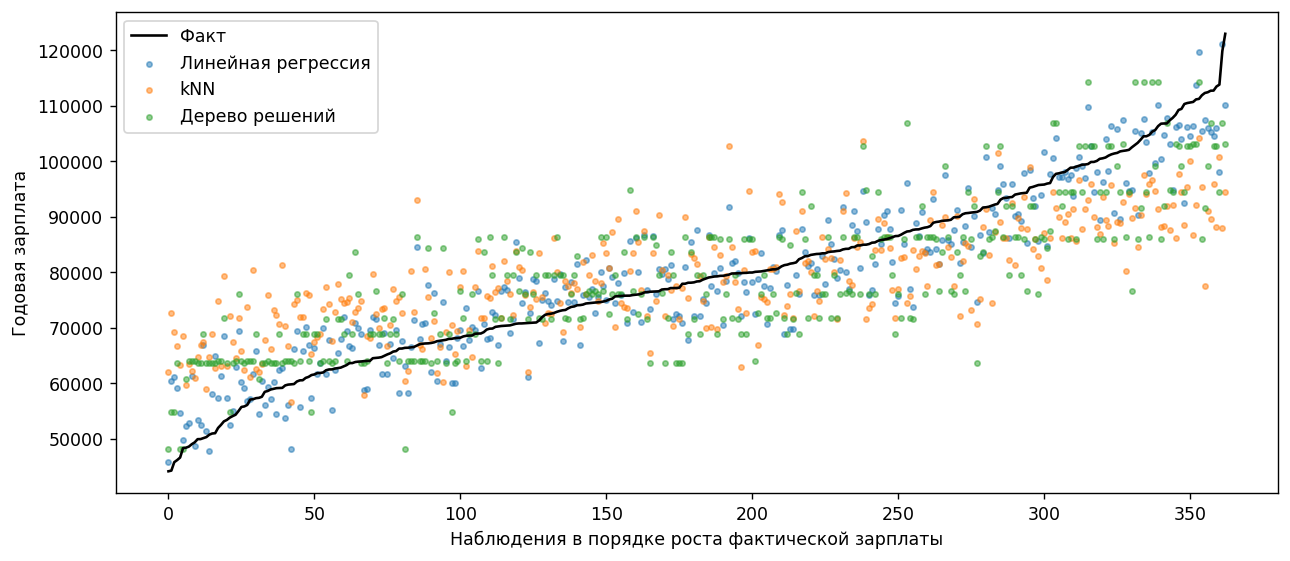

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, prediction) in zip(axes, predictions.items()):
    ax.scatter(y_valid, prediction, s=15, alpha=0.5, label='Прогнозы на валидации')
    lo = min(y_valid.min(), prediction.min())
    hi = max(y_valid.max(), prediction.max())
    ax.plot([lo, hi], [lo, hi], color='red', label='Идеальное совпадение')
    ax.set(xlabel='Фактическая зарплата', ylabel='Прогноз зарплаты', title=name)
    ax.set_aspect('equal', adjustable='box')
    ax.locator_params(axis='both', nbins=4)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

order = np.argsort(y_valid.to_numpy())
plt.figure(figsize=(12, 5))
plt.plot(y_valid.to_numpy()[order], color='black', label='Факт')
for name, prediction in predictions.items():
    plt.scatter(np.arange(len(order)), prediction[order], s=9, alpha=0.5, label=name)
plt.xlabel('Наблюдения в порядке роста фактической зарплаты')
plt.ylabel('Годовая зарплата')
plt.legend()
plt.show()


### 14. Вывод по задаче зарплаты
Методы сравниваются на одной валидационной части очищенного набора. Предпочтительный метод определяется по MAE и сопоставляется с RMSE и R². Эти результаты относятся к отфильтрованным зарплатам, а не к редким большим значениям исходного набора. Отбирать строки по ошибкам конкретной модели нельзя.

Лучшая модель — линейная регрессия: MAE = 4915,83, RMSE = 6117,15, R² = 0,8591.

In [10]:
best = result_table['MAE'].idxmin()
print('Наименьшая MAE:', best)
print('MAE:', round(result_table.loc[best, 'MAE'], 2))
print('R2:', round(result_table.loc[best, 'R2'], 4))
print('Наименьшая RMSE:', result_table['RMSE'].idxmin())
print('Три самых больших по модулю коэффициента среди числовых признаков:')
display(coefficients[coefficients['Признак'].isin(numeric_columns)].nlargest(3, 'Модуль'))


Наименьшая MAE: Линейная регрессия
MAE: 4915.83
R2: 0.8591
Наименьшая RMSE: Линейная регрессия
Три самых больших по модулю коэффициента среди числовых признаков:


,Признак,Коэффициент,Модуль
2,experience,10293.710290,10293.710290
1,income,7334.341444,7334.341444
3,score_test,1093.627752,1093.627752


## Дополнительное задание №11. Функция обучения и проверки
Функция model_train_test(X_train, y_train, X_test, y_test, model) обучает переданную модель, выводит MAE, MSE, RMSE и R² отдельно на обучающей и проверочной частях, а также полные таблицы «факт — прогноз — разность». Применяю её к данным второй части: x2 → y, полином степени 2. Аргумент X_test здесь означает прежнюю валидационную часть, а не новую независимую выборку.

In [11]:
def model_train_test(X_train, y_train, X_test, y_test, model):
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    scores = []
    tables = {}
    for name, X_part, y_part in [('Обучение', X_train, y_train),
                                ('Проверка', X_test, y_test)]:
        predicted = fitted_model.predict(X_part)
        scores.append({'Выборка': name, **metrics(y_part, predicted)})
        table = pd.DataFrame({'Факт': y_part, 'Прогноз': predicted})
        table['Прогноз − факт'] = table['Прогноз'] - table['Факт']
        tables[name] = table.sort_index()
        print(name)
        with pd.option_context('display.max_rows', None):
            display(tables[name])
    score_table = pd.DataFrame(scores).set_index('Выборка')
    display(score_table)
    return fitted_model, score_table, tables

polynomial_model = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                                 LinearRegression())
extra11_model, extra11_scores, extra11_tables = model_train_test(
    df.loc[train_index, ['x2']], y_train_reg,
    df.loc[valid_index, ['x2']], y_valid_reg, polynomial_model
)

Обучение
Проверка


,Факт,Прогноз,Прогноз − факт
0,0.870770,-0.218185,-1.088955
1,0.539647,1.892459,1.352811
4,1.737131,1.352883,-0.384248
5,3.748636,2.098612,-1.650025
6,0.988839,1.260248,0.271409
7,-0.842644,-0.955778,-0.113134
8,-0.704140,-0.144255,0.559885
9,0.244140,-1.200887,-1.445028
11,-1.160850,-0.070757,1.090093
12,0.024653,0.236435,0.211782


,Факт,Прогноз,Прогноз − факт
2,1.049902,0.918800,-0.131102
3,-1.490034,-1.038126,0.451909
10,2.025431,2.786148,0.760716
23,-1.819759,-0.991554,0.828205
25,4.607668,0.989846,-3.617822
29,0.501901,0.263219,-0.238681
30,3.285727,2.847379,-0.438348
31,-0.787755,-1.751539,-0.963784
33,2.874938,2.156447,-0.718492
39,0.572998,0.180583,-0.392415


,MAE,MSE,RMSE,R2
Выборка,,,,
Обучение,0.685776,0.759664,0.871587,0.718418
Проверка,0.698166,0.825600,0.908626,0.729167


## Дополнительное задание №12. Случайный лес
Обучаю RandomForestRegressor на тех же 1089 строках, что и остальные модели зарплаты; проверка — те же 363 строки. Использую 300 деревьев, min_samples_leaf = 2 и random_state = 42. Это фиксированные параметры без подбора по проверочной части. Среднее прогнозов деревьев уменьшает разброс отдельных деревьев. Для всех четырёх моделей рассчитываю одинаковые четыре метрики.

Лучшая модель по MAE: Линейная регрессия


,MAE,MSE,RMSE,R2
Модель,,,,
Линейная регрессия,4915.832025,3.741947e+07,6117.145476,0.859079
kNN,8861.392840,1.173129e+08,10831.107575,0.558202
Дерево решений,7662.382661,8.766863e+07,9363.152800,0.669842
Случайный лес,5879.332502,5.278988e+07,7265.664362,0.801194


,Факт,Прогноз,Прогноз − факт
15,63876.307670,63952.705402,76.397732
23,111198.257761,110620.781056,-577.476705
29,44219.056055,59506.910579,15287.854524
30,90837.188701,73315.405227,-17521.783474
31,94294.390163,81793.572175,-12500.817987
32,91766.966835,86068.838876,-5698.127959
44,71288.910020,71093.144526,-195.765494
45,68075.399817,61081.838574,-6993.561243
49,83843.268389,77816.866524,-6026.401865
50,90409.785269,84874.697101,-5535.088168


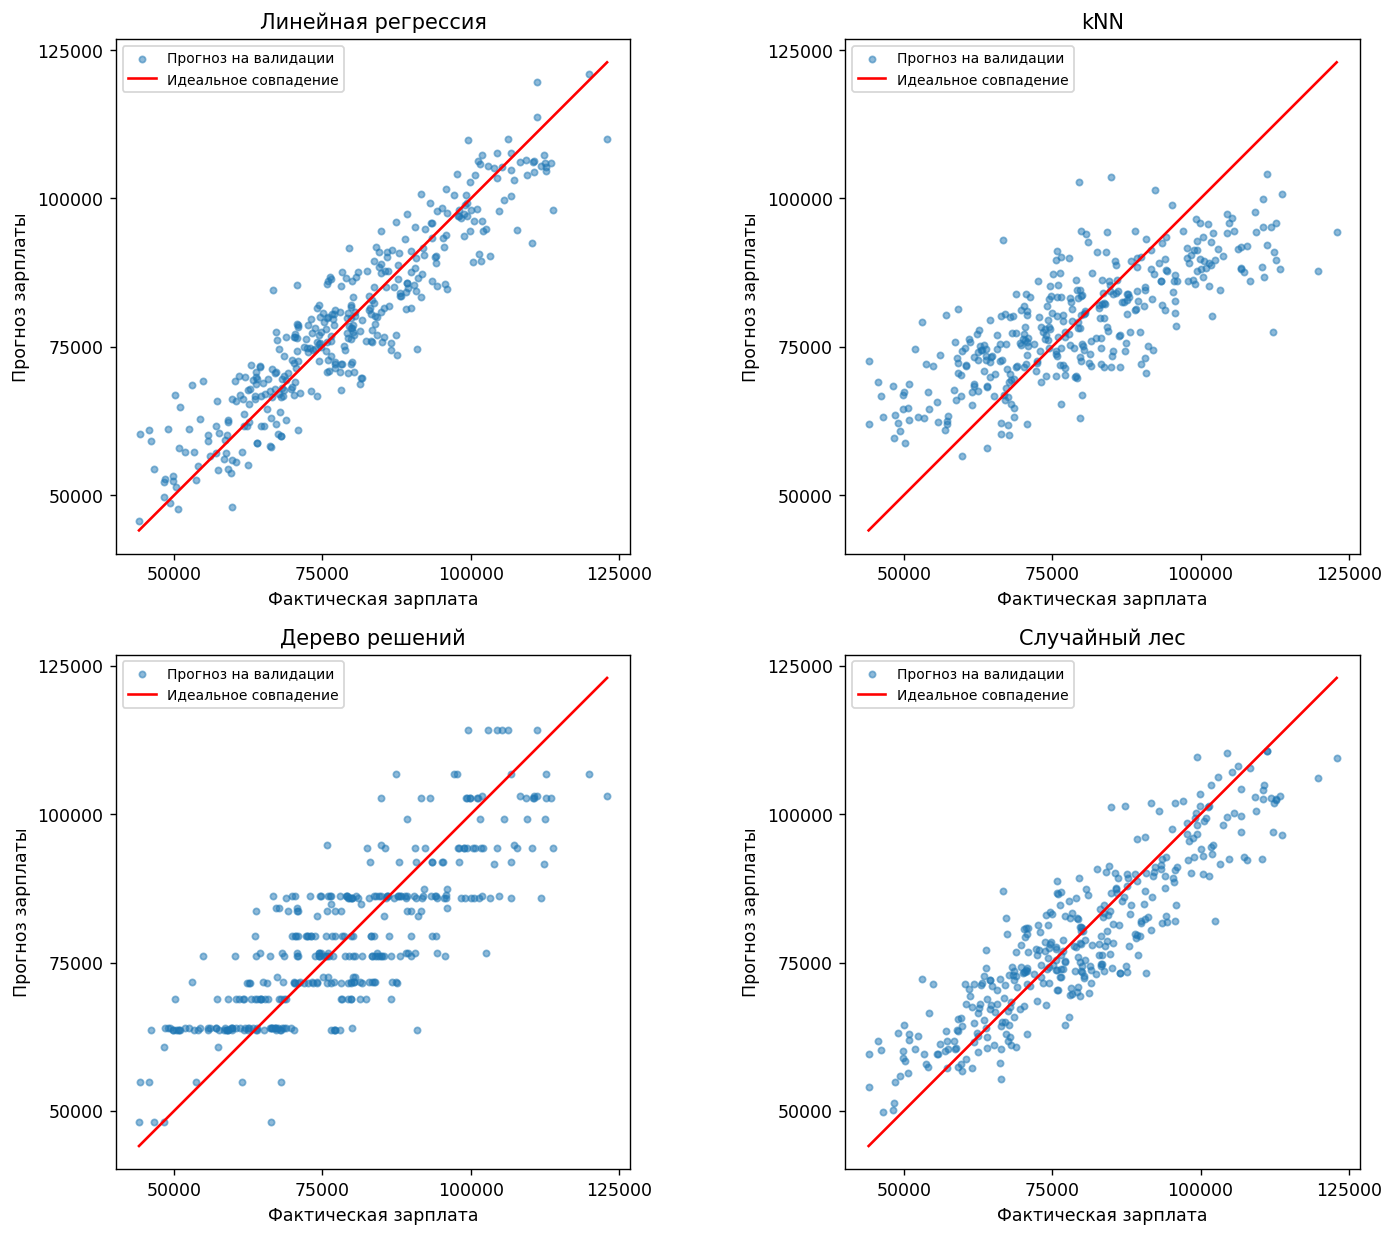

In [12]:
forest = RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                               random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
forest_prediction = forest.predict(X_valid)
models['Случайный лес'] = forest
predictions['Случайный лес'] = forest_prediction
all_results = pd.concat([result_table, pd.DataFrame(
    [metrics(y_valid, forest_prediction)], index=['Случайный лес'])])
all_results.index.name = 'Модель'
display(all_results)
forest_comparison = pd.DataFrame({'Факт': y_valid, 'Прогноз': forest_prediction})
forest_comparison['Прогноз − факт'] = forest_comparison['Прогноз'] - forest_comparison['Факт']
with pd.option_context('display.max_rows', None):
    display(forest_comparison.sort_index())
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, prediction) in zip(axes.flat, predictions.items()):
    ax.scatter(y_valid, prediction, s=13, alpha=0.5, label='Прогноз на валидации')
    lo = min(y_valid.min(), prediction.min())
    hi = max(y_valid.max(), prediction.max())
    ax.plot([lo, hi], [lo, hi], color='red', label='Идеальное совпадение')
    ax.set(xlabel='Фактическая зарплата', ylabel='Прогноз зарплаты', title=name)
    ax.set_aspect('equal', adjustable='box')
    ax.locator_params(axis='both', nbins=4)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Лучшая модель по MAE:', all_results.MAE.idxmin())

## Дополнительное задание №15. Категории сотрудников и их важность
Показываю частоты всех шести категориальных признаков в очищенных данных; исходные частоты тоже вывожу для сравнения. Столбчатые диаграммы характеризуют состав сотрудников, а не причину различий зарплаты. Для каждой категории вычисляю число сотрудников и среднюю зарплату.

Влияние категориальных столбцов на качество оцениваю групповой перестановкой: одновременно перемешиваю все dummy-столбцы одного исходного признака одной перестановкой строк, сохраняя допустимые сочетания 0/1. Важность = MAE после перестановки − исходная MAE. Положительное значение означает ухудшение прогноза, отрицательное — отсутствие устойчивой пользы на этой проверке. Делаю 10 повторений и указываю стандартное отклонение. Модель фиксирована, по этой оценке ничего не подбираю.

Дополнительно сравниваю линейную регрессию со всеми признаками и только с числовыми на одинаковых строках. Коэффициенты категорий показываю относительно базового уровня; это связи с прогнозом при прочих равных, а не доказательство причинного влияния.

education
city
job_type
marital_status
car
remote_work
Преобладающие категории после очистки:
education : Bachelor
city : New York
job_type : IT
marital_status : Married
car : Yes
remote_work : Yes


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
education,,,,
Bachelor,875,78658.31,60.26,900
High School,193,71836.80,13.29,200
Master,192,84131.94,13.22,200
PhD,192,91082.11,13.22,200


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
city,,,,
Chicago,241,80097.01,16.60,250
Houston,192,80117.76,13.22,200
Los Angeles,292,79257.94,20.11,300
New York,580,80786.61,39.94,600
Phoenix,147,79225.04,10.12,150


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
job_type,,,,
Education,97,78599.09,6.68,100
Finance,194,80970.08,13.36,200
Healthcare,193,78065.03,13.29,200
IT,490,83028.63,33.75,500
Retail,478,77926.22,32.92,500


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
marital_status,,,,
Divorced,140,78412.72,9.64,144
Married,694,80046.33,47.80,717
Single,618,80585.25,42.56,639


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
car,,,,
No,431,82176.88,29.68,450
Yes,1021,79249.15,70.32,1050


,Количество,Средняя_зарплата,Доля_процентов,Количество_до_очистки
remote_work,,,,
No,601,79378.86,41.39,617
Yes,851,80640.34,58.61,883


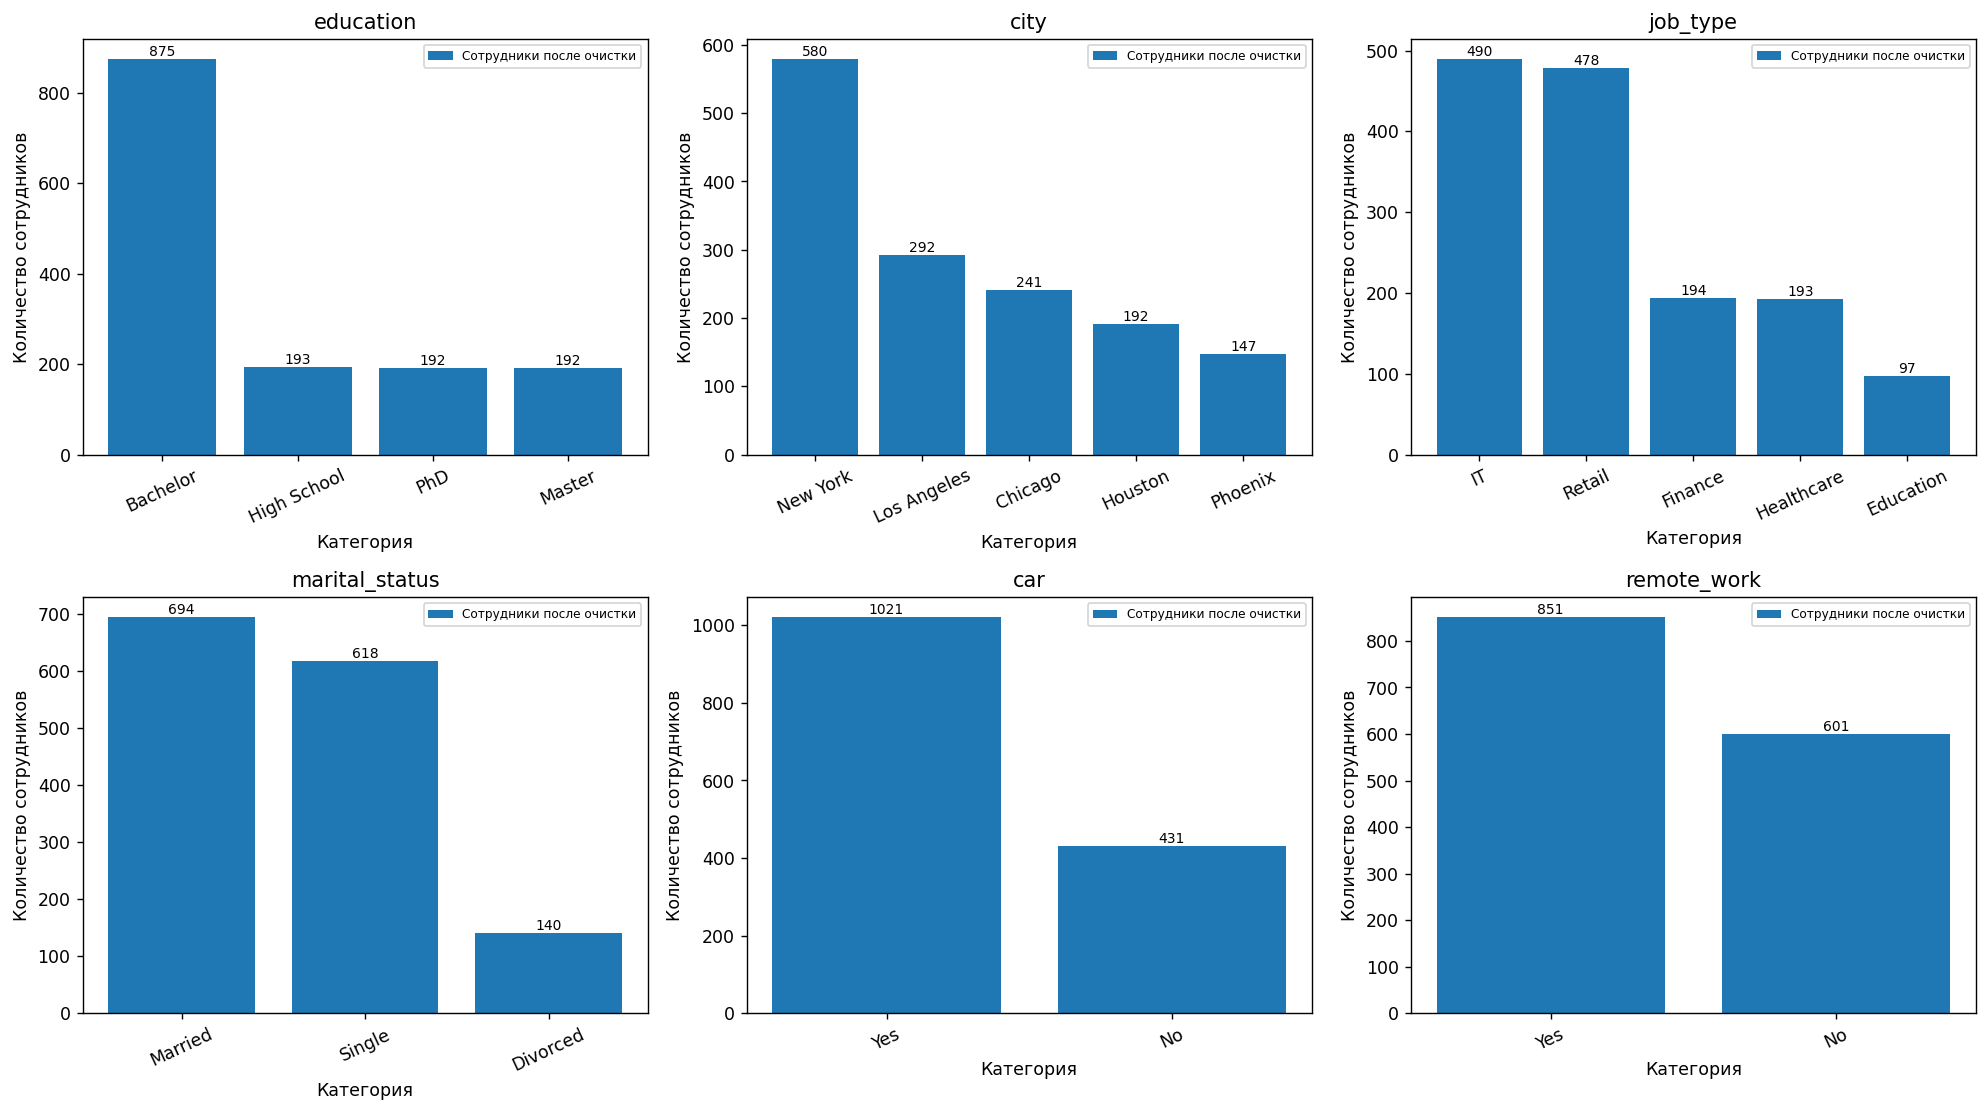

,MAE,MSE,RMSE,R2
Все признаки,4915.832025,3.741947e+07,6117.145476,0.859079
Только числовые,6794.737103,7.272259e+07,8527.754224,0.726128


,Модель,Признак,Рост MAE,Стандартное отклонение
0,Линейная регрессия,education,2910.52,132.43
1,Линейная регрессия,city,24.39,29.29
2,Линейная регрессия,job_type,658.53,109.22
3,Линейная регрессия,marital_status,0.00,1.15
4,Линейная регрессия,car,-44.06,23.20
5,Линейная регрессия,remote_work,-6.12,4.64
6,Случайный лес,education,1861.40,141.97
7,Случайный лес,city,6.02,11.27
8,Случайный лес,job_type,214.77,37.14
9,Случайный лес,marital_status,-5.39,13.04


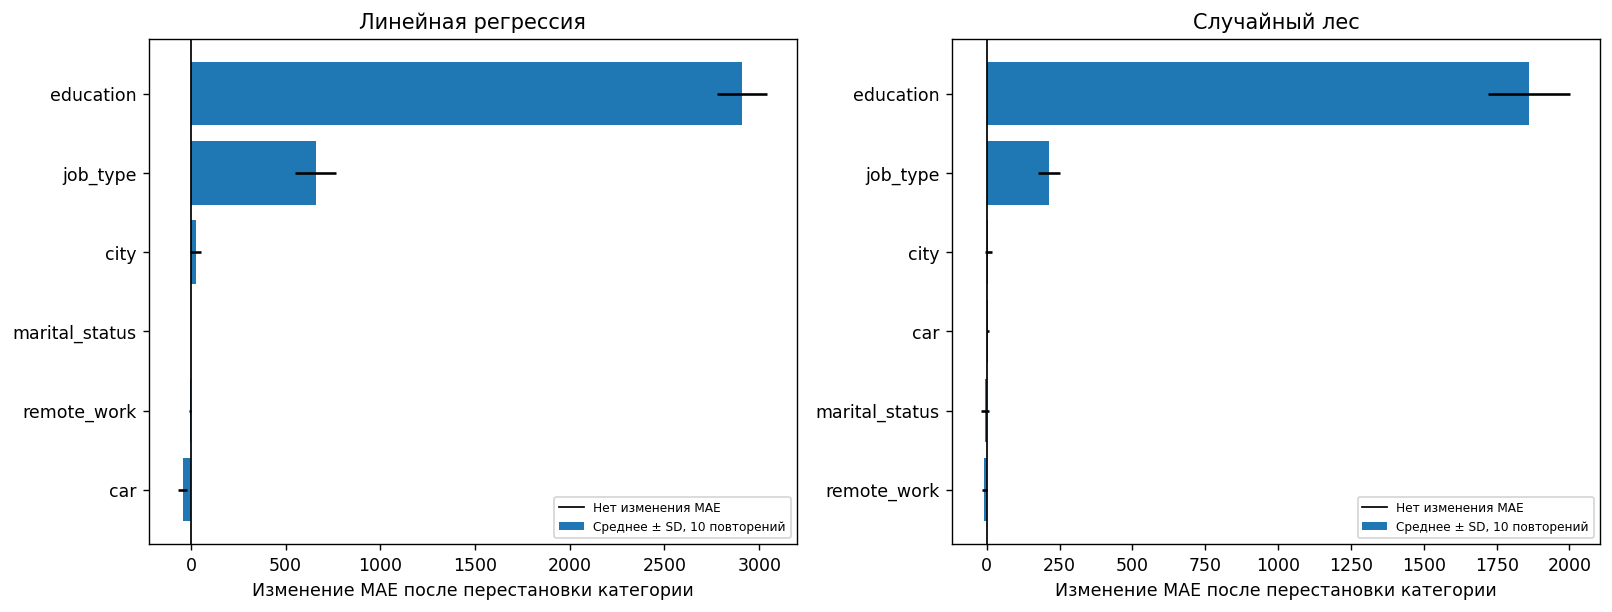

,Признак,Коэффициент,Модуль
10,education_PhD,12614.640214,12614.640214
9,education_Master,6587.020517,6587.020517
8,education_High School,-6250.536544,6250.536544
17,job_type_IT,3715.258270,3715.258270
15,job_type_Finance,2123.121149,2123.121149
13,city_New York,1393.721422,1393.721422
21,car_Yes,-1123.949400,1123.949400
18,job_type_Retail,-1075.259405,1075.259405
12,city_Los Angeles,1049.705064,1049.705064
14,city_Phoenix,849.426604,849.426604


In [13]:
category_columns = salary.select_dtypes(include='object').columns.tolist()
category_tables = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, column in zip(axes.flat, category_columns):
    counts = salary[column].value_counts()
    ax.bar(counts.index, counts.values, label='Сотрудники после очистки')
    ax.set(title=column, xlabel='Категория', ylabel='Количество сотрудников')
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=7)
    for i, value in enumerate(counts.values):
        ax.text(i, value, str(value), ha='center', va='bottom', fontsize=8)
    table = salary.groupby(column)['salary'].agg(Количество='size', Средняя_зарплата='mean')
    table['Доля_процентов'] = table['Количество'] / len(salary) * 100
    table['Количество_до_очистки'] = salary_raw[column].value_counts()
    category_tables[column] = table
    print(column)
    display(table.round(2))
plt.tight_layout()
plt.show()

numeric_model = LinearRegression().fit(X_train[numeric_columns], y_train)
numeric_prediction = numeric_model.predict(X_valid[numeric_columns])
category_ablation = pd.DataFrame([
    metrics(y_valid, predictions['Линейная регрессия']),
    metrics(y_valid, numeric_prediction)], index=['Все признаки', 'Только числовые'])
display(category_ablation)

importance_rows = []
for name in ['Линейная регрессия', 'Случайный лес']:
    model = models[name]
    baseline_mae = mean_absolute_error(y_valid, predictions[name])
    for column in category_columns:
        dummy_columns = [c for c in X_valid.columns if c.startswith(column + '_')]
        rng = np.random.default_rng(42)
        differences = []
        for repeat in range(10):
            order = rng.permutation(len(X_valid))
            permuted = X_valid.copy()
            permuted[dummy_columns] = X_valid[dummy_columns].to_numpy()[order]
            changed_mae = mean_absolute_error(y_valid, model.predict(permuted))
            differences.append(changed_mae - baseline_mae)
        importance_rows.append({'Модель': name, 'Признак': column,
                                'Рост MAE': np.mean(differences),
                                'Стандартное отклонение': np.std(differences)})
category_importance = pd.DataFrame(importance_rows)
display(category_importance.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ['Линейная регрессия', 'Случайный лес']):
    values = category_importance[category_importance['Модель'] == name].sort_values('Рост MAE')
    ax.barh(values['Признак'], values['Рост MAE'],
            xerr=values['Стандартное отклонение'], label='Среднее ± SD, 10 повторений')
    ax.axvline(0, color='black', linewidth=1, label='Нет изменения MAE')
    ax.set(title=name, xlabel='Изменение MAE после перестановки категории')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

category_coefficients = coefficients[~coefficients['Признак'].isin(numeric_columns)].copy()
display(category_coefficients.sort_values('Модуль', ascending=False))
print('Преобладающие категории после очистки:')
for column in category_columns:
    print(column, ':', salary[column].value_counts().idxmax())

## Общий вывод
Модель по x2 точнее модели по x1; полиномы второй и третьей степени не дают заметного улучшения. Функция из задания №11 применена ко второй части.

Выбросы зарплаты обработаны до разбиения по правилу 1,5 IQR: из 1500 строк исключены 48, осталось 1452 (1089 train, 363 valid). Графики до и после обработки сохранены, исходный salary_raw не изменён. Метрики относятся только к очищенному диапазону зарплат. Прогнозы не использовались для отбора строк.

Сравнены четыре метода зарплаты, включая случайный лес из задания №12. По заданию №15 рассмотрены все шесть категориальных признаков, их частоты, средние зарплаты и влияние на ошибку фиксированных моделей. Наблюдаемые связи не интерпретируются как причинные. Конкретные результаты расчёта приведены ниже.

Лучший метод зарплаты по MAE: Линейная регрессия; MAE=4915.83, RMSE=6117.15, R²=0.8591. Преобладающие категории: education — Bachelor, city — New York, job_type — IT, marital_status — Married, car — Yes, remote_work — Yes.

In [14]:
print('Итоговое сравнение моделей зарплаты:')
display(all_results.sort_values('MAE'))
print('Лучший метод по MAE:', all_results.MAE.idxmin())
print('Исключено строк:', len(excluded_salary))
print('Сохранено:', len(salary), 'train:', len(y_train), 'valid:', len(y_valid))

Итоговое сравнение моделей зарплаты:
Лучший метод по MAE: Линейная регрессия
Исключено строк: 48
Сохранено: 1452 train: 1089 valid: 363


,MAE,MSE,RMSE,R2
Модель,,,,
Линейная регрессия,4915.832025,3.741947e+07,6117.145476,0.859079
Случайный лес,5879.332502,5.278988e+07,7265.664362,0.801194
Дерево решений,7662.382661,8.766863e+07,9363.152800,0.669842
kNN,8861.392840,1.173129e+08,10831.107575,0.558202
